# Influence Score Correlation Analysis

This notebook analyzes the correlation between different influence score types and the performance metrics from the golden layer analysis.

## Objectives:
1. Load influence scores from TracInInf files (one at a time for memory efficiency)
2. Compute correlation with performance metrics (for proxy, test, and all samples)
3. Identify best layers selected by each influence score type (min and max)
4. Present results in comprehensive tables

In [34]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import warnings
import gc
warnings.filterwarnings('ignore')

# Import the golden layer API
from golden_layer_api import GoldenLayerAnalyzer

# Naming conversion function
def convert_influence_name(internal_name):
    """
    Convert internal influence type names to readable format.
    
    Mapping:
    - OverallNew -> Overall_new
    - OverallOrig/OverallHat -> overall_hat
    - OverallTruth -> overall_truth
    - THAT -> y_hat
    - TNew -> y_new
    - TTruth -> y_truth
    - Query -> Query
    - CausalTraceProba.last -> CMA (last subject token)
    - HiddenStates -> HS
    - l2normSpecific -> L2-Norm
    - specific -> TracIn
    """
    # Handle CausalTraceProba
    if 'CausalTraceProba' in internal_name:
        return 'CMA (last subject token)'
    
    # Handle HiddenStates
    if internal_name.startswith('HiddenStates.'):
        parts = internal_name.split('.')
        if len(parts) == 3:
            hs_type = parts[1]  # HSMlp, HSAttn, etc.
            target = parts[2]
            
            # Map the target
            target_map = {
                'OverallNew': 'overall_new',
                'OverallOrig': 'overall_hat',
                'OverallHat': 'overall_hat'
            }
            mapped_target = target_map.get(target, target)
            
            # Simplify HS type
            hs_map = {
                'HSMlp': 'HS-MLP',
                'HSAttn': 'HS-Attn',
                'HSHs': 'HS-HS',
                'HSDiffMlp': 'HS-Diff-MLP',
                'HSDiffAttn': 'HS-Diff-Attn',
                'HSDiffHs': 'HS-Diff-HS'
            }
            hs_str = hs_map.get(hs_type, hs_type)
            
            return f'{hs_str} ({mapped_target})'
    
    # Handle l2normSpecific and specific
    prefix = ''
    if internal_name.startswith('l2normSpecific.'):
        prefix = 'L2-Norm'
        remainder = internal_name[15:]  # Remove 'l2normSpecific.'
    elif internal_name.startswith('specific.'):
        prefix = 'TracIn'
        remainder = internal_name[9:]  # Remove 'specific.'
    else:
        return internal_name
    
    # Split by camelCase
    parts = []
    current = ''
    for char in remainder:
        if char.isupper() and current:
            parts.append(current)
            current = char
        else:
            current += char
    if current:
        parts.append(current)
    
    # Map each part
    part_map = {
        'Overall': 'overall',
        'OverallNew': 'overall_new',
        'OverallHat': 'overall_hat',
        'OverallOrig': 'overall_hat',
        'OverallTruth': 'overall_truth',
        'THAT': 'y_hat',
        'TNew': 'y_new',
        'TTruth': 'y_truth',
        'Query': 'Query'
    }
    
    mapped_parts = [part_map.get(part, part.lower()) for part in parts]
    
    # Format the result
    if len(mapped_parts) == 1:
        return f'{prefix} ({mapped_parts[0]})'
    else:
        return f'{prefix} ({mapped_parts[0]} & {mapped_parts[1]})'

## 1. Load Performance Metrics from Golden Layer Analysis

In [35]:
# Load the golden layer analysis results
print("Loading WikiBio golden layer analysis results...")

# Import WikiBio-specific analyzer
import sys
sys.path.insert(0, '/home/user/Projects/EasyEditEdited/sampleLayerRelationshipWikiBio/golden_layer')
from golden_layer_api_wikibio import GoldenLayerAnalyzerWikiBio

analyzer = GoldenLayerAnalyzerWikiBio(data_dir='../allLayerPerformance')
(analyzer
    .load_data(verbose=False)
    .compute_overall_metric(verbose=False)
    .split_dataset(proxy_size=30, random_seed=42, verbose=True)
    .compute_proxy_test_means(verbose=False)
    .analyze(verbose=False))

print("\nWikiBio golden layer analysis loaded successfully!")
print(f"Proxy indices: {len(analyzer.proxy_indices)} samples")
print(f"Test indices: {len(analyzer.test_indices)} samples")

Loading WikiBio golden layer analysis results...

Dataset split:
  Total samples: 306
  Proxy set: 30 samples
  Test set: 276 samples

WikiBio golden layer analysis loaded successfully!
Proxy indices: 30 samples
Test indices: 276 samples


## 2. Define Influence Score Types

In [36]:
# Directory containing influence scores
influence_dir = Path('../../lga_scores')

# Find all available influence score types for gpt2-xl WikiBio with 306 samples
influence_files = list(influence_dir.glob('modelName-gpt2-xl_dataset-wikibio_*_nsamples-306.pt'))

# Extract overall types from filenames
influence_types = []
for f in influence_files:
    fname = f.name
    # Extract overall-<type> part
    if 'overall-' in fname:
        overall_part = fname.split('overall-')[1].split('_layers')[0]
        
        # Skip test files
        if overall_part.endswith('test'):
            continue
            
        influence_types.append(overall_part)

influence_types = sorted(set(influence_types))

print(f"Found {len(influence_types)} influence score types for WikiBio:")
for i, inf_type in enumerate(influence_types, 1):
    print(f"  {i:2d}. {inf_type}")

Found 21 influence score types for WikiBio:
   1. CausalTraceProba.last
   2. l2normSpecific.OverallHat
   3. l2normSpecific.OverallNew
   4. l2normSpecific.OverallTruth
   5. l2normSpecific.Query
   6. l2normSpecific.THAT
   7. l2normSpecific.TNew
   8. l2normSpecific.TTruth
   9. specific.OverallNewOverallHat
  10. specific.OverallNewTHAT
  11. specific.OverallTruthOverallHat
  12. specific.OverallTruthOverallNew
  13. specific.OverallTruthTNew
  14. specific.QueryOverallHat
  15. specific.QueryOverallNew
  16. specific.QueryOverallTruth
  17. specific.QueryTHAT
  18. specific.THATOverallHat
  19. specific.TNewOverallNew
  20. specific.TTruthOverallTruth
  21. specific.TTruthTNew


## 3. Load Influence Scores Function (Memory Efficient)

In [37]:
def load_influence_scores(overall_type, influence_dir):
    """
    Load influence scores for WikiBio dataset.
    
    Args:
        overall_type: The overall score type (e.g., 'specific.QueryOverallHat')
        influence_dir: Directory containing influence files
    
    Returns:
        torch.Tensor of shape (n_samples, n_layers) or None if not found/error
    """
    # WikiBio pattern
    pattern = f'modelName-gpt2-xl_dataset-wikibio_*_overall-{overall_type}_layers-48__nsamples-306.pt'
    files = list(influence_dir.glob(pattern))
    
    if not files:
        return None, f"No file found for {overall_type}"
    
    try:
        # Load the first matching file
        data = torch.load(files[0], map_location='cpu')
        
        # Handle different storage formats
        scores = None
        
        if isinstance(data, torch.Tensor):
            scores = data
        elif isinstance(data, list):
            # CausalTraceProba.last returns list of tensors
            if len(data) > 0:
                if isinstance(data[0], torch.Tensor):
                    if data[0].dim() == 1:
                        scores = torch.stack(data)
                    elif data[0].dim() == 2:
                        # Take last token for each sample
                        last_token_scores = [sample_scores[-1] for sample_scores in data]
                        scores = torch.stack(last_token_scores)
        elif isinstance(data, dict):
            for key in ['scores', 'influence', 'data', 'influences']:
                if key in data:
                    if isinstance(data[key], torch.Tensor):
                        scores = data[key]
                        break
                    elif isinstance(data[key], list) and len(data[key]) > 0:
                        if isinstance(data[key][0], torch.Tensor):
                            if data[key][0].dim() == 1:
                                scores = torch.stack(data[key])
                            elif data[key][0].dim() == 2:
                                last_token_scores = [s[-1] for s in data[key]]
                                scores = torch.stack(last_token_scores)
                        break
        
        if scores is None:
            return None, f"Could not extract tensor from {type(data)}"
        
        # Verify shape for WikiBio (306 samples, 48 layers)
        if scores.shape != (306, 48):
            return None, f"Unexpected shape {scores.shape}, expected (306, 48)"
        
        return scores, None
        
    except Exception as e:
        return None, f"Error loading: {str(e)}"

# Test loading one file
print("Testing influence score loading for WikiBio...")
if len(influence_types) > 0:
    test_type = influence_types[0]
    test_scores, error = load_influence_scores(test_type, influence_dir)
    if test_scores is not None:
        print(f"✓ Successfully loaded {test_type}: shape {test_scores.shape}")
    else:
        print(f"✗ Failed to load {test_type}: {error}")
else:
    print("No influence types found!")

Testing influence score loading for WikiBio...
✓ Successfully loaded CausalTraceProba.last: shape torch.Size([306, 48])


## 4. Compute Correlations with Performance Metrics

In [38]:
def compute_correlation(influence_scores, performance_means):
    """
    Compute correlation between influence scores and performance metrics.
    
    Args:
        influence_scores: Tensor of shape (n_samples, n_layers)
        performance_means: Tensor of shape (n_layers,) - mean performance per layer
    
    Returns:
        Pearson correlation coefficient
    """
    # Average influence scores across samples to get per-layer scores
    influence_means = torch.nanmean(influence_scores, dim=0).numpy()
    performance_means_np = performance_means.numpy()
    
    # Remove NaN values
    valid_mask = ~(np.isnan(influence_means) | np.isnan(performance_means_np))
    
    if valid_mask.sum() < 2:
        return np.nan
    
    # Compute Pearson correlation
    corr, _ = stats.pearsonr(influence_means[valid_mask], performance_means_np[valid_mask])
    
    return corr


# Compute correlations for all influence types (one at a time)
print("Computing correlations with performance metrics...\n")
print("Progress:")

correlation_results = []
failed_types = []

for idx, inf_type in enumerate(influence_types, 1):
    print(f"  [{idx:2d}/{len(influence_types)}] Processing {inf_type[:50]}...", end=' ')
    
    # Load influence scores
    scores, error = load_influence_scores(inf_type, influence_dir)
    
    if scores is None:
        print(f"FAILED: {error}")
        failed_types.append({'Influence Type': inf_type, 'Error': error})
        continue
    
    result = {'Influence Type': inf_type}
    
    # Compute correlations for each performance metric
    for metric_key, metric_name in analyzer.metrics_info:
        # All samples
        all_scores = scores
        all_means = torch.nanmean(analyzer.results[metric_key], dim=0)
        corr_all = compute_correlation(all_scores, all_means)
        result[f'{metric_name} (All)'] = corr_all
        
        # Proxy samples
        proxy_scores = scores[analyzer.proxy_indices, :]
        corr_proxy = compute_correlation(proxy_scores, analyzer.proxy_means[metric_key])
        result[f'{metric_name} (Proxy)'] = corr_proxy
        
        # Test samples
        test_scores = scores[analyzer.test_indices, :]
        corr_test = compute_correlation(test_scores, analyzer.test_means[metric_key])
        result[f'{metric_name} (Test)'] = corr_test
    
    correlation_results.append(result)
    print("OK")
    
    # Free memory
    del scores
    gc.collect()

print(f"\n✓ Computed correlations for {len(correlation_results)} influence types.")
if failed_types:
    print(f"✗ Failed to load {len(failed_types)} influence types.")

Computing correlations with performance metrics...

Progress:
  [ 1/21] Processing CausalTraceProba.last... OK
  [ 2/21] Processing l2normSpecific.OverallHat... OK
  [ 3/21] Processing l2normSpecific.OverallNew... OK
  [ 4/21] Processing l2normSpecific.OverallTruth... OK
  [ 5/21] Processing l2normSpecific.Query... OK
  [ 6/21] Processing l2normSpecific.THAT... OK
  [ 7/21] Processing l2normSpecific.TNew... OK
  [ 8/21] Processing l2normSpecific.TTruth... OK
  [ 9/21] Processing specific.OverallNewOverallHat... OK
  [10/21] Processing specific.OverallNewTHAT... OK
  [11/21] Processing specific.OverallTruthOverallHat... OK
  [12/21] Processing specific.OverallTruthOverallNew... OK
  [13/21] Processing specific.OverallTruthTNew... OK
  [14/21] Processing specific.QueryOverallHat... OK
  [15/21] Processing specific.QueryOverallNew... OK
  [16/21] Processing specific.QueryOverallTruth... OK
  [17/21] Processing specific.QueryTHAT... OK
  [18/21] Processing specific.THATOverallHat... OK
  [

## 5. Display Correlation Results Table

In [39]:
# Create DataFrame
df_correlations = pd.DataFrame(correlation_results)

# Display full table
print("="*150)
print("CORRELATION BETWEEN INFLUENCE SCORES AND PERFORMANCE METRICS")
print("="*150)
print("\nNote: Correlations computed using layer-wise means")
print("Positive correlation: Higher influence score → Better performance")
print("Negative correlation: Lower influence score → Better performance\n")

# Show with better formatting
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.precision', 4)
print(df_correlations.to_string(index=False))

# Show failed types if any
if failed_types:
    print("\n" + "="*150)
    print("FAILED TO LOAD:")
    print("="*150)
    df_failed = pd.DataFrame(failed_types)
    print(df_failed.to_string(index=False))

CORRELATION BETWEEN INFLUENCE SCORES AND PERFORMANCE METRICS

Note: Correlations computed using layer-wise means
Positive correlation: Higher influence score → Better performance
Negative correlation: Lower influence score → Better performance

                 Influence Type  Rewrite Accuracy (All)  Rewrite Accuracy (Proxy)  Rewrite Accuracy (Test)  Locality (All)  Locality (Proxy)  Locality (Test)  Fluency (All)  Fluency (Proxy)  Fluency (Test)  Overall (All)  Overall (Proxy)  Overall (Test)
          CausalTraceProba.last                 -0.1230                    0.3197                  -0.1430          0.2149            0.0691           0.2199        -0.1014           0.0962         -0.1093         0.1778           0.4017          0.1632
      l2normSpecific.OverallHat                 -0.1790                   -0.3316                  -0.1634          0.6869            0.5646           0.6944         0.2718           0.1035          0.2812         0.5671           0.3145          

## 6. Find Best Layers Selected by Each Influence Type

In [40]:
def find_best_layers(influence_scores, influence_type):
    """
    Find the best layer(s) based on influence scores.
    
    For CausalTraceProba: higher score = better (use MAX)
    For all other methods: lower score = better (use MIN)
    
    Args:
        influence_scores: Tensor of shape (n_samples, n_layers)
        influence_type: The influence type string (e.g., 'CausalTraceProba.last', 'specific.QueryOverallHat')
    
    Returns:
        List of best layer indices
    """
    # Average across samples
    layer_means = torch.nanmean(influence_scores, dim=0).numpy()
    
    # Determine mode based on influence type
    if 'CausalTraceProba' in influence_type:
        # CausalTraceProba: higher score = better layer
        best_value = np.nanmax(layer_means)
    else:
        # All other methods: lower score = better layer
        best_value = np.nanmin(layer_means)
    
    # Find all layers with best value (handle ties)
    best_layers = np.where(layer_means == best_value)[0].tolist()
    
    return best_layers


# Find best layers for each influence type (one at a time)
print("Finding best layers selected by each influence type...\n")
print("Note: CausalTraceProba uses MAX (higher=better), all others use MIN (lower=better)")
print("\nProgress:")

best_layer_results = []

for idx, inf_type in enumerate(influence_types, 1):
    print(f"  [{idx:2d}/{len(influence_types)}] Processing {inf_type[:50]}...", end=' ')
    
    # Load influence scores
    scores, error = load_influence_scores(inf_type, influence_dir)
    
    if scores is None:
        print("SKIP")
        continue
    
    result = {'Influence Type': inf_type}
    
    # All samples - now using influence type to determine mode
    result['Best Layer (All)'] = str(find_best_layers(scores, inf_type))
    
    # Proxy samples
    proxy_scores = scores[analyzer.proxy_indices, :]
    result['Best Layer (Proxy)'] = str(find_best_layers(proxy_scores, inf_type))
    
    # Test samples
    test_scores = scores[analyzer.test_indices, :]
    result['Best Layer (Test)'] = str(find_best_layers(test_scores, inf_type))
    
    best_layer_results.append(result)
    print("OK")
    
    # Free memory
    del scores
    gc.collect()

print(f"\n✓ Found best layers for {len(best_layer_results)} influence types.")

Finding best layers selected by each influence type...

Note: CausalTraceProba uses MAX (higher=better), all others use MIN (lower=better)

Progress:
  [ 1/21] Processing CausalTraceProba.last... OK
  [ 2/21] Processing l2normSpecific.OverallHat... OK
  [ 3/21] Processing l2normSpecific.OverallNew... OK
  [ 4/21] Processing l2normSpecific.OverallTruth... OK
  [ 5/21] Processing l2normSpecific.Query... OK
  [ 6/21] Processing l2normSpecific.THAT... OK
  [ 7/21] Processing l2normSpecific.TNew... OK
  [ 8/21] Processing l2normSpecific.TTruth... OK
  [ 9/21] Processing specific.OverallNewOverallHat... OK
  [10/21] Processing specific.OverallNewTHAT... OK
  [11/21] Processing specific.OverallTruthOverallHat... OK
  [12/21] Processing specific.OverallTruthOverallNew... OK
  [13/21] Processing specific.OverallTruthTNew... OK
  [14/21] Processing specific.QueryOverallHat... OK
  [15/21] Processing specific.QueryOverallNew... OK
  [16/21] Processing specific.QueryOverallTruth... OK
  [17/21] Pr

## 7. Display Best Layer Results Table

In [41]:
# Create DataFrame
df_best_layers = pd.DataFrame(best_layer_results)

# Display full table
print("="*150)
print("BEST LAYERS SELECTED BY INFLUENCE SCORES")
print("="*150)
print("\nNote: Best layers determined by averaging influence scores across samples")
print("CausalTraceProba: Layer with HIGHEST average influence score (higher = better)")
print("All other methods: Layer with LOWEST average influence score (lower = better)\n")

pd.set_option('display.max_rows', None)
print(df_best_layers.to_string(index=False))

BEST LAYERS SELECTED BY INFLUENCE SCORES

Note: Best layers determined by averaging influence scores across samples
CausalTraceProba: Layer with HIGHEST average influence score (higher = better)
All other methods: Layer with LOWEST average influence score (lower = better)

                 Influence Type Best Layer (All) Best Layer (Proxy) Best Layer (Test)
          CausalTraceProba.last              [6]                [6]               [6]
      l2normSpecific.OverallHat              [0]               [12]               [0]
      l2normSpecific.OverallNew              [0]                [0]               [0]
    l2normSpecific.OverallTruth              [0]               [12]               [0]
           l2normSpecific.Query              [0]               [12]               [0]
            l2normSpecific.THAT             [46]               [46]              [46]
            l2normSpecific.TNew              [0]                [0]               [0]
          l2normSpecific.TTruth       

## 8. Compare with Golden Layer

In [42]:
# Get golden layer from analyzer
golden_layer_proxy = analyzer.best_layers_comparison['post_overall']['proxy_best_layers']
golden_layer_test = analyzer.best_layers_comparison['post_overall']['test_best_layers']

print("="*70)
print("GOLDEN LAYER COMPARISON")
print("="*70)
print(f"\nGolden Layer (Proxy): {golden_layer_proxy}")
print(f"Golden Layer (Test): {golden_layer_test}")

# Find influence types that select the golden layer
print("\n\nInfluence types that select the golden layer:")
print("-" * 70)

matches = []
for result in best_layer_results:
    inf_type = result['Influence Type']
    
    # Check if best layer matches golden layer
    for layer_col in ['Best Layer (All)', 'Best Layer (Proxy)', 'Best Layer (Test)']:
        layers_str = result[layer_col]
        layers = eval(layers_str)  # Convert string back to list
        
        # Check overlap with golden layers
        overlap_proxy = set(layers) & set(golden_layer_proxy)
        overlap_test = set(layers) & set(golden_layer_test)
        
        if overlap_proxy:
            matches.append({
                'Influence Type': inf_type,
                'Selection Type': layer_col,
                'Selected Layers': layers_str,
                'Matches': f'Proxy Golden Layer {list(overlap_proxy)}'
            })
        
        if overlap_test:
            matches.append({
                'Influence Type': inf_type,
                'Selection Type': layer_col,
                'Selected Layers': layers_str,
                'Matches': f'Test Golden Layer {list(overlap_test)}'
            })

if matches:
    df_matches = pd.DataFrame(matches)
    # Remove duplicates
    df_matches = df_matches.drop_duplicates()
    print(df_matches.to_string(index=False))
else:
    print("No influence types select the golden layer.")

GOLDEN LAYER COMPARISON

Golden Layer (Proxy): [23]
Golden Layer (Test): [23]


Influence types that select the golden layer:
----------------------------------------------------------------------
No influence types select the golden layer.


## 9. Summary Statistics

In [43]:
print("="*70)
print("SUMMARY STATISTICS")
print("="*70)

# Correlation summary for Overall metric
overall_cols = [col for col in df_correlations.columns if 'Overall' in col and col != 'Influence Type']

for col in overall_cols:
    values = df_correlations[col].dropna()
    if len(values) > 0:
        print(f"\n{col}:")
        print(f"  Mean correlation: {values.mean():.4f}")
        print(f"  Std correlation: {values.std():.4f}")
        print(f"  Max correlation: {values.max():.4f}")
        print(f"  Min correlation: {values.min():.4f}")
        
        # Find best correlating influence type
        max_idx = values.idxmax()
        min_idx = values.idxmin()
        print(f"  Best positive correlation: {df_correlations.iloc[max_idx]['Influence Type']} ({values.max():.4f})")
        print(f"  Best negative correlation: {df_correlations.iloc[min_idx]['Influence Type']} ({values.min():.4f})")

SUMMARY STATISTICS

Overall (All):
  Mean correlation: 0.2939
  Std correlation: 0.4350
  Max correlation: 0.6904
  Min correlation: -0.6580
  Best positive correlation: specific.OverallTruthTNew (0.6904)
  Best negative correlation: l2normSpecific.TTruth (-0.6580)

Overall (Proxy):
  Mean correlation: 0.1287
  Std correlation: 0.3573
  Max correlation: 0.6049
  Min correlation: -0.6727
  Best positive correlation: specific.QueryTHAT (0.6049)
  Best negative correlation: specific.TTruthOverallTruth (-0.6727)

Overall (Test):
  Mean correlation: 0.3060
  Std correlation: 0.4393
  Max correlation: 0.7019
  Min correlation: -0.6564
  Best positive correlation: specific.OverallTruthTNew (0.7019)
  Best negative correlation: l2normSpecific.TTruth (-0.6564)


## 10. Save Results

In [44]:
# Save to CSV files
output_dir = Path('./influence_analysis_results')
output_dir.mkdir(exist_ok=True)

df_correlations.to_csv(output_dir / 'influence_correlations.csv', index=False)
print(f"Saved: {output_dir / 'influence_correlations.csv'}")

df_best_layers.to_csv(output_dir / 'influence_best_layers.csv', index=False)
print(f"Saved: {output_dir / 'influence_best_layers.csv'}")

if failed_types:
    df_failed = pd.DataFrame(failed_types)
    df_failed.to_csv(output_dir / 'failed_influence_types.csv', index=False)
    print(f"Saved: {output_dir / 'failed_influence_types.csv'}")

print("\nAll results saved successfully!")

Saved: influence_analysis_results/influence_correlations.csv
Saved: influence_analysis_results/influence_best_layers.csv

All results saved successfully!


## 11. Visualize Top Correlations

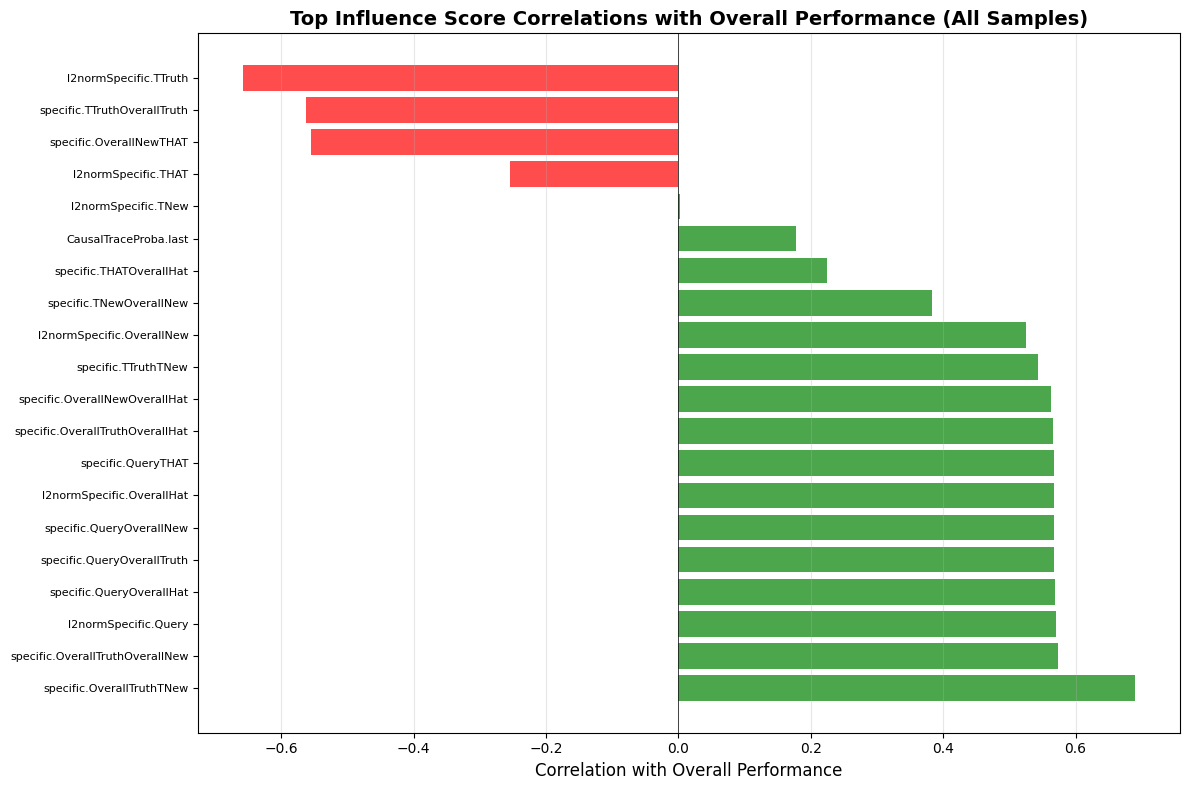


Saved: influence_analysis_results/top_correlations.png


In [45]:
# Plot top 10 positive and negative correlations for Overall metric
overall_col = 'Overall (All)'

if overall_col in df_correlations.columns:
    # Sort by correlation
    df_sorted = df_correlations.sort_values(overall_col, ascending=False)
    
    # Get top 10 positive and bottom 10 (most negative)
    top_10 = df_sorted.head(10)
    bottom_10 = df_sorted.tail(10)
    
    # Combine
    df_plot = pd.concat([top_10, bottom_10])
    
    # Create plot
    fig, ax = plt.subplots(figsize=(12, 8))
    
    y_pos = np.arange(len(df_plot))
    colors = ['green' if x > 0 else 'red' for x in df_plot[overall_col]]
    
    ax.barh(y_pos, df_plot[overall_col], color=colors, alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([t[:50] for t in df_plot['Influence Type']], fontsize=8)
    ax.set_xlabel('Correlation with Overall Performance', fontsize=12)
    ax.set_title('Top Influence Score Correlations with Overall Performance (All Samples)', 
                fontsize=14, fontweight='bold')
    ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.savefig(output_dir / 'top_correlations.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\nSaved: {output_dir / 'top_correlations.png'}")

## Analysis Complete

This notebook has:
1. ✓ Loaded influence scores from TracInInf files (one at a time for memory efficiency)
2. ✓ Handled special cases:
   - HiddenStates files with 49 layers (stripped embedding layer)
   - CausalTraceProba.last format (list of tensors)
3. ✓ Computed correlations with performance metrics (proxy, test, all samples)
4. ✓ Identified best layers selected by each influence score type (min and max)
5. ✓ Compared with golden layers from performance analysis
6. ✓ Saved results to CSV files

In [46]:
# Create comprehensive top correlations table with performance metrics
overall_col = 'Overall (All)'

# Sort by correlation
df_sorted = df_correlations.sort_values(overall_col, ascending=False)

# Get top 5 positive and top 5 (or fewer) negative
n_top = 11
top_positive = df_sorted.head(n_top)

# For negative, check how many negatives exist
negative_df = df_sorted[df_sorted[overall_col] < 0]
n_neg = min(n_top, len(negative_df))
top_negative = negative_df.tail(n_neg)  # Most negative

# Combine
df_top_combined = pd.concat([top_positive, top_negative])

# Create summary table
summary_rows = []

for idx, row in df_top_combined.iterrows():
    inf_type = row['Influence Type']
    
    # Convert name
    readable_name = inf_type
    
    # Get correlations
    corr_all = row.get('Overall (All)', np.nan)
    corr_proxy = row.get('Overall (Proxy)', np.nan)
    corr_test = row.get('Overall (Test)', np.nan)
    
    # Find corresponding best layers
    best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
    
    if not best_layer_row.empty:
        # Now we just use 'Best Layer' columns (already determined by influence type)
        layers_all = best_layer_row['Best Layer (All)'].values[0]
        layers_proxy = best_layer_row['Best Layer (Proxy)'].values[0]
        layers_test = best_layer_row['Best Layer (Test)'].values[0]
        
        # Determine selection mode for display
        if 'CausalTraceProba' in inf_type:
            selection_mode = 'Max'
        else:
            selection_mode = 'Min'
    else:
        layers_all = 'N/A'
        layers_proxy = 'N/A'
        layers_test = 'N/A'
        selection_mode = 'N/A'
    
    # Get performance at the selected layer for ALL metrics
    # This shows how the selected layer (TEST SET) performs on each metric
    perf_metrics = {}
    
    if layers_test != 'N/A':
        try:
            layer_idx = eval(layers_test)[0]  # Take first layer if multiple
            
            # Get performance for all metrics at this layer for TEST SET
            for metric_key, metric_name in analyzer.metrics_info:
                test_means = analyzer.test_means[metric_key]
                perf_value = test_means[layer_idx].item()
                
                # Use short names for columns
                if metric_name == 'Rewrite Accuracy':
                    perf_metrics['Rewrite'] = f"{perf_value:.4f}"
                elif metric_name == 'Locality':
                    perf_metrics['Locality'] = f"{perf_value:.4f}"
                elif metric_name == 'Fluency':
                    perf_metrics['Fluency'] = f"{perf_value:.4f}"
                elif metric_name == 'Overall':
                    perf_metrics['Overall'] = f"{perf_value:.4f}"
        except Exception as e:
            # If any error, set all to N/A
            for name in ['Rewrite', 'Locality', 'Fluency', 'Overall']:
                perf_metrics[name] = 'N/A'
    else:
        for name in ['Rewrite', 'Locality', 'Fluency', 'Overall']:
            perf_metrics[name] = 'N/A'
    
    summary_rows.append({
        'Method': readable_name,
        'Mode': selection_mode,
        'Corr (All)': f"{corr_all:.4f}",
        'Corr (Proxy)': f"{corr_proxy:.4f}",
        'Corr (Test)': f"{corr_test:.4f}",
        'Layer (All)': layers_all,
        'Layer (Proxy)': layers_proxy,
        'Layer (Test)': layers_test,
        'Rewrite': perf_metrics.get('Rewrite', 'N/A'),
        'Locality': perf_metrics.get('Locality', 'N/A'),
        'Fluency': perf_metrics.get('Fluency', 'N/A'),
        'Overall_Perf': perf_metrics.get('Overall', 'N/A')
    })

df_summary_top = pd.DataFrame(summary_rows)

print("="*200)
print("TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE")
print("="*200)
print(f"\nTop {len(top_positive)} Positive and Top {n_neg} Negative correlations")
print("Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance")
print("\nPerformance columns (Rewrite, Locality, Fluency, Overall_Perf):")
print("  Show the actual performance at the selected layer (TEST SET) for ALL metrics")
print("  This lets you see how the layer performs across all metrics on the test set")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(df_summary_top.to_string(index=False))

# Save to CSV
df_summary_top.to_csv(output_dir / 'top_correlations_summary.csv', index=False)
print(f"\n\nSaved: {output_dir / 'top_correlations_summary.csv'}")

TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE

Top 11 Positive and Top 4 Negative correlations
Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance

Performance columns (Rewrite, Locality, Fluency, Overall_Perf):
  Show the actual performance at the selected layer (TEST SET) for ALL metrics
  This lets you see how the layer performs across all metrics on the test set


                         Method Mode Corr (All) Corr (Proxy) Corr (Test) Layer (All) Layer (Proxy) Layer (Test) Rewrite Locality Fluency Overall_Perf
      specific.OverallTruthTNew  Min     0.6904       0.4306      0.7019         [0]          [12]          [0]  0.4061   0.2563  5.9014       0.2532
specific.OverallTruthOverallNew  Min     0.5728       0.3225      0.5899         [0]          [12]          [0]  0.4061   0.2563  5.9014       0.2532
           l2normSpecific.Query  Min     0.5703       0.3119      0.5876         [0]          [12]        

## 12. Top Positive and Negative Correlations Summary

This section presents the top 5 positive and top 5 negative correlations with the Overall performance metric, including:
- Readable method names (following the naming convention from the results table)
- Correlation values for All, Proxy, and Test sets
- Best layers selected for All, Proxy, and Test sets

In [47]:
# Create comprehensive top correlations table with performance metrics
overall_col = 'Overall (All)'

# Sort by correlation
df_sorted = df_correlations.sort_values(overall_col, ascending=False)

# Get top 5 positive and top 5 (or fewer) negative
n_top = 19
top_positive = df_sorted.head(n_top)

# For negative, check how many negatives exist
negative_df = df_sorted[df_sorted[overall_col] < 0]
n_neg = min(n_top, len(negative_df))
top_negative = negative_df.tail(n_neg)  # Most negative

# Combine
df_top_combined = pd.concat([top_positive, top_negative])

# First, get the baseline performance from CausalTraceProba.last
baseline_overall_perf = None
for idx, row in df_top_combined.iterrows():
    if row['Influence Type'] == 'CausalTraceProba.last':
        inf_type = row['Influence Type']
        
        best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
        if not best_layer_row.empty:
            layers_test = best_layer_row['Best Layer (Test)'].values[0]
            
            if layers_test != 'N/A':
                try:
                    layer_idx = eval(layers_test)[0]
                    test_means = analyzer.test_means['post_overall']
                    baseline_overall_perf = test_means[layer_idx].item()
                except:
                    pass
        break

print(f"Baseline CausalTraceProba.last Overall Performance (Test Set): {baseline_overall_perf:.4f}\n")

# Create summary table
summary_rows = []

for idx, row in df_top_combined.iterrows():
    inf_type = row['Influence Type']
    
    # Find corresponding best layers
    best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
    
    if not best_layer_row.empty:
        layers_all = best_layer_row['Best Layer (All)'].values[0]
        layers_proxy = best_layer_row['Best Layer (Proxy)'].values[0]
        layers_test = best_layer_row['Best Layer (Test)'].values[0]
        
        # Determine selection mode for display
        if 'CausalTraceProba' in inf_type:
            selection_mode = 'Max'
        else:
            selection_mode = 'Min'
    else:
        layers_all = 'N/A'
        layers_proxy = 'N/A'
        layers_test = 'N/A'
        selection_mode = 'N/A'
    
    # Get performance at the selected layer for ALL metrics
    perf_metrics = {}
    current_overall_perf = None
    
    if layers_test != 'N/A':
        try:
            layer_idx = eval(layers_test)[0]  # Take first layer if multiple
            
            # Get performance for all metrics at this layer for TEST SET
            for metric_key, metric_name in analyzer.metrics_info:
                test_means = analyzer.test_means[metric_key]
                perf_value = test_means[layer_idx].item()
                
                # Store current overall performance for comparison
                if metric_name == 'Overall':
                    current_overall_perf = perf_value
                
                # Use short names for columns
                if metric_name == 'Rewrite Accuracy':
                    perf_metrics['Rewrite'] = f"{perf_value:.4f}"
                elif metric_name == 'Locality':
                    perf_metrics['Locality'] = f"{perf_value:.4f}"
                elif metric_name == 'Fluency':
                    perf_metrics['Fluency'] = f"{perf_value:.4f}"
                elif metric_name == 'Overall':
                    perf_metrics['Overall'] = f"{perf_value:.4f}"
        except Exception as e:
            # If any error, set all to N/A
            for name in ['Rewrite', 'Locality', 'Fluency', 'Overall']:
                perf_metrics[name] = 'N/A'
    else:
        for name in ['Rewrite', 'Locality', 'Fluency', 'Overall']:
            perf_metrics[name] = 'N/A'
    
    # Only add if overall performance is better than or equal to baseline
    if current_overall_perf is not None and current_overall_perf >= baseline_overall_perf:
        summary_rows.append({
            'Method': inf_type,
            'Mode': selection_mode,
            'Layer (All)': layers_all,
            'Layer (Proxy)': layers_proxy,
            'Layer (Test)': layers_test,
            'Rewrite': perf_metrics.get('Rewrite', 'N/A'),
            'Locality': perf_metrics.get('Locality', 'N/A'),
            'Fluency': perf_metrics.get('Fluency', 'N/A'),
            'Overall_Perf': perf_metrics.get('Overall', 'N/A')
        })

df_summary_top = pd.DataFrame(summary_rows)

print("="*200)
print("METHODS WITH OVERALL PERFORMANCE >= BASELINE")
print("="*200)
print(f"\nBaseline: CausalTraceProba.last (Overall: {baseline_overall_perf:.4f})")
print("\nPerformance columns (Rewrite, Locality, Fluency, Overall_Perf):")
print("  Show the actual performance at the selected layer (TEST SET) for ALL metrics")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(df_summary_top.to_string(index=False))

# Save to CSV
df_summary_top.to_csv(output_dir / 'methods_above_baseline.csv', index=False)
print(f"\n\nSaved: {output_dir / 'methods_above_baseline.csv'}")

Baseline CausalTraceProba.last Overall Performance (Test Set): 0.4198

METHODS WITH OVERALL PERFORMANCE >= BASELINE

Baseline: CausalTraceProba.last (Overall: 0.4198)

Performance columns (Rewrite, Locality, Fluency, Overall_Perf):
  Show the actual performance at the selected layer (TEST SET) for ALL metrics


                     Method Mode Layer (All) Layer (Proxy) Layer (Test) Rewrite Locality Fluency Overall_Perf
    specific.THATOverallHat  Min        [19]          [46]         [19]  0.8256   0.6736  6.3349       0.5493
      CausalTraceProba.last  Max         [6]           [6]          [6]  0.6894   0.5692  6.3465       0.4198
        l2normSpecific.THAT  Min        [46]          [46]         [46]  0.5056   0.9882  6.3447       0.4787
    specific.OverallNewTHAT  Min        [40]          [46]         [40]  0.5778   0.9574  6.3040       0.5104
        l2normSpecific.THAT  Min        [46]          [46]         [46]  0.5056   0.9882  6.3447       0.4787
    specific.OverallNewTHAT

## 13. Proxy-Based Layer Selection with Layer 17 Comparison

This section uses the PROXY set's best layer to evaluate performance on the TEST set.
Additionally shows performance at layer 17 for comparison.

In [ ]:
# Create table with proxy-based layer selection and layer 17 performance
overall_col = 'Overall (All)'

# Sort by correlation
df_sorted = df_correlations.sort_values(overall_col, ascending=False)

# Get top 19 positive and negatives
n_top = 21
top_positive = df_sorted.head(n_top)

# For negative, check how many negatives exist
negative_df = df_sorted[df_sorted[overall_col] < 0]
n_neg = min(n_top, len(negative_df))
top_negative = negative_df.tail(n_neg)  # Most negative

# Combine
df_top_combined = pd.concat([top_positive, top_negative])

# First, get the baseline performance from CausalTraceProba.last
baseline_overall_perf = None
for idx, row in df_top_combined.iterrows():
    if row['Influence Type'] == 'CausalTraceProba.last':
        inf_type = row['Influence Type']
        
        best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
        if not best_layer_row.empty:
            layers_test = best_layer_row['Best Layer (Test)'].values[0]
            
            if layers_test != 'N/A':
                try:
                    layer_idx = eval(layers_test)[0]
                    test_means = analyzer.test_means['post_overall']
                    baseline_overall_perf = test_means[layer_idx].item()
                except:
                    pass
        break

print(f"Baseline CausalTraceProba.last Overall Performance (Test Set): {baseline_overall_perf:.4f}\n")

# Create summary table with proxy-based selection and layer 17
summary_rows = []

for idx, row in df_sorted.iterrows():
    inf_type = row['Influence Type']
    
    # Find corresponding best layers
    best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
    
    if not best_layer_row.empty:
        layers_all = best_layer_row['Best Layer (All)'].values[0]
        layers_proxy = best_layer_row['Best Layer (Proxy)'].values[0]
        
        # USE PROXY'S BEST LAYER for test set selection
        layers_test_from_proxy = layers_proxy
        
        # Determine selection mode for display
        if 'CausalTraceProba' in inf_type:
            selection_mode = 'Max'
        else:
            selection_mode = 'Min'
    else:
        layers_all = 'N/A'
        layers_proxy = 'N/A'
        layers_test_from_proxy = 'N/A'
        selection_mode = 'N/A'
    
    # Get performance at PROXY-SELECTED layer on TEST SET
    perf_metrics_proxy_layer = {}
    current_overall_perf = None
    
    if layers_test_from_proxy != 'N/A':
        try:
            layer_idx = eval(layers_test_from_proxy)[0]  # Take first layer if multiple
            
            # Get performance for all metrics at this layer for TEST SET
            for metric_key, metric_name in analyzer.metrics_info:
                test_means = analyzer.test_means[metric_key]
                perf_value = test_means[layer_idx].item()
                
                # Store current overall performance for comparison
                if metric_name == 'Overall':
                    current_overall_perf = perf_value
                
                # Use short names for columns
                if metric_name == 'Rewrite Accuracy':
                    perf_metrics_proxy_layer['Rewrite'] = f"{perf_value:.4f}"
                elif metric_name == 'Locality':
                    perf_metrics_proxy_layer['Locality'] = f"{perf_value:.4f}"
                elif metric_name == 'Fluency':
                    perf_metrics_proxy_layer['Fluency'] = f"{perf_value:.4f}"
                elif metric_name == 'Overall':
                    perf_metrics_proxy_layer['Overall'] = f"{perf_value:.4f}"
        except Exception as e:
            for name in ['Rewrite', 'Locality', 'Fluency', 'Overall']:
                perf_metrics_proxy_layer[name] = 'N/A'
    else:
        for name in ['Rewrite', 'Locality', 'Fluency', 'Overall']:
            perf_metrics_proxy_layer[name] = 'N/A'
    
    # Get performance at LAYER 17 on TEST SET
    perf_metrics_layer17 = {}
    layer17_overall_perf = None
    
    try:
        layer_idx = 17
        
        # Get performance for all metrics at layer 17 for TEST SET
        for metric_key, metric_name in analyzer.metrics_info:
            test_means = analyzer.test_means[metric_key]
            perf_value = test_means[layer_idx].item()
            
            # Store layer 17 overall performance
            if metric_name == 'Overall':
                layer17_overall_perf = perf_value
            
            # Use short names for columns
            if metric_name == 'Rewrite Accuracy':
                perf_metrics_layer17['Rewrite_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Locality':
                perf_metrics_layer17['Locality_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Fluency':
                perf_metrics_layer17['Fluency_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Overall':
                perf_metrics_layer17['Overall_L17'] = f"{perf_value:.4f}"
    except Exception as e:
        for name in ['Rewrite_L17', 'Locality_L17', 'Fluency_L17', 'Overall_L17']:
            perf_metrics_layer17[name] = 'N/A'
    
    # Only add if overall performance is better than or equal to baseline
    if current_overall_perf is not None and current_overall_perf >= baseline_overall_perf:
        summary_rows.append({
            'Method': inf_type,
            'Mode': selection_mode,
            'Layer (Proxy)': layers_proxy,
            'Rewrite': perf_metrics_proxy_layer.get('Rewrite', 'N/A'),
            'Locality': perf_metrics_proxy_layer.get('Locality', 'N/A'),
            'Fluency': perf_metrics_proxy_layer.get('Fluency', 'N/A'),
            'Overall': perf_metrics_proxy_layer.get('Overall', 'N/A'),
            'Rewrite_L17': perf_metrics_layer17.get('Rewrite_L17', 'N/A'),
            'Locality_L17': perf_metrics_layer17.get('Locality_L17', 'N/A'),
            'Fluency_L17': perf_metrics_layer17.get('Fluency_L17', 'N/A'),
            'Overall_L17': perf_metrics_layer17.get('Overall_L17', 'N/A')
        })

df_summary_proxy = pd.DataFrame(summary_rows)

print("="*250)
print("METHODS WITH PERFORMANCE >= BASELINE (USING PROXY-SELECTED LAYER ON TEST SET)")
print("="*250)
print(f"\nBaseline: CausalTraceProba.last (Overall: {baseline_overall_perf:.4f})")
print("\nLayer Selection: Test set evaluated at the layer selected by PROXY set")
print("Performance columns (Rewrite, Locality, Fluency, Overall): Performance at proxy-selected layer")
print("Performance columns with _L17 suffix: Performance at layer 17 (for comparison)")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 250)
print(df_summary_proxy.to_string(index=False))

# Save to CSV
df_summary_proxy.to_csv(output_dir / 'methods_proxy_selection_with_layer17.csv', index=False)
print(f"\n\nSaved: {output_dir / 'methods_proxy_selection_with_layer17.csv'}")

Baseline CausalTraceProba.last Overall Performance (Test Set): 0.4198

METHODS WITH PERFORMANCE >= BASELINE (USING PROXY-SELECTED LAYER ON TEST SET)

Baseline: CausalTraceProba.last (Overall: 0.4198)

Layer Selection: Test set evaluated at the layer selected by PROXY set
Performance columns (Rewrite, Locality, Fluency, Overall): Performance at proxy-selected layer
Performance columns with _L17 suffix: Performance at layer 17 (for comparison)


                         Method Mode Layer (Proxy) Rewrite Locality Fluency Overall Rewrite_L17 Locality_L17 Fluency_L17 Overall_L17
      specific.OverallTruthTNew  Min          [12]  0.7484   0.5587  6.3339  0.4554      0.8192       0.6289      6.3303      0.5279
specific.OverallTruthOverallNew  Min          [12]  0.7484   0.5587  6.3339  0.4554      0.8192       0.6289      6.3303      0.5279
           l2normSpecific.Query  Min          [12]  0.7484   0.5587  6.3339  0.4554      0.8192       0.6289      6.3303      0.5279
       specific.Quer

In [49]:
# Function to convert influence names to readable format
def convert_influence_to_readable(internal_name):
    target_map = {
        'OverallNew': 'overall_new',
        'OverallOrig': 'overall_hat',
        'OverallHat': 'overall_hat',
        'OverallTruth': 'overall_truth',
        'THAT': 'y_hat',
        'TNew': 'y_new',
        'TTruth': 'y_truth',
        'Query': 'Query'
    }
    
    # Handle CausalTraceProba
    if 'CausalTraceProba' in internal_name:
        return 'CMA (last subject token)'

    # Handle l2normSpecific
    if internal_name.startswith('l2normSpecific.'):
        remainder = internal_name[len('l2normSpecific.'):]
        mapped = target_map.get(remainder, remainder.lower())
        return f'L2-Norm ({mapped})'

    # Handle specific
    if internal_name.startswith('specific.'):
        remainder = internal_name[len('specific.'):]
        
        # Try to extract known target_map keys
        parts = []
        i = 0
        while i < len(remainder):
            for key in sorted(target_map.keys(), key=lambda x: -len(x)):
                if remainder.startswith(key, i):
                    parts.append(target_map[key])
                    i += len(key)
                    break
            else:
                # fallback: take one char to avoid infinite loop
                parts.append(remainder[i].lower())
                i += 1

        if len(parts) >= 2:
            return f'Inf ({parts[0]} & {parts[1]})'
        elif len(parts) == 1:
            return f'Inf ({parts[0]})'
        else:
            return internal_name

    return internal_name


def format_with_ranking(df, column, higher_is_better=True):
    """
    Format values in a column with bold for best and underline for second-best.
    
    Args:
        df: DataFrame
        column: Column name to format
        higher_is_better: If True, higher values are better. If False, lower values are better.
    
    Returns:
        Series with formatted values
    """
    # Convert to numeric, handling string values
    values = pd.to_numeric(df[column], errors='coerce')
    
    # Get unique sorted values
    unique_values = sorted(values.dropna().unique(), reverse=higher_is_better)
    
    if len(unique_values) == 0:
        return df[column]
    
    # Get best and second-best values
    best_value = unique_values[0] if len(unique_values) > 0 else None
    second_best_value = unique_values[1] if len(unique_values) > 1 else None
    
    # Format the column
    formatted = []
    for val in df[column]:
        try:
            num_val = float(val)
            if best_value is not None and num_val == best_value:
                formatted.append(f'**{val}**')
            elif second_best_value is not None and num_val == second_best_value:
                formatted.append(f'<u>{val}</u>')
            else:
                formatted.append(str(val))
        except (ValueError, TypeError):
            formatted.append(str(val))
    
    return formatted


# Create markdown table from the dataframe
def create_markdown_table(df):
    """
    Create a formatted markdown table with:
    - CausalTraceProba at the beginning
    - Other methods in the middle
    - Layer 17 as a separate row at the end
    - Bold for best values, underline for second-best
    """
    # Make a copy and add readable names
    df_copy = df.copy()
    df_copy['Readable_Name'] = df_copy['Method'].apply(convert_influence_to_readable)
    
    # Separate CausalTraceProba and others
    causal_rows = df_copy[df_copy['Method'].str.contains('CausalTraceProba')]
    other_rows = df_copy[~df_copy['Method'].str.contains('CausalTraceProba')]
    
    # Sort others by Overall performance (descending)
    other_rows = other_rows.sort_values('Overall', ascending=False)
    
    # Combine: CausalTraceProba first, then others
    df_sorted = pd.concat([causal_rows, other_rows])
    
    # Remove duplicates
    df_sorted = df_sorted.drop_duplicates(subset=['Method'])
    
    # Select columns WITHOUT L17 suffix
    columns_order = [
        'Readable_Name',
        'Mode',
        'Layer (Proxy)',
        'Rewrite',
        'Locality',
        'Fluency',
        'Overall'
    ]
    
    df_display = df_sorted[columns_order].copy()
    
    # Rename columns for display
    df_display.columns = [
        'Method',
        'Mode',
        'Layer',
        'Rewrite',
        'Locality',
        'Fluency',
        'Overall'
    ]
    
    # Create Layer 17 row (using first row's L17 values since they're all the same)
    if len(df_sorted) > 0:
        first_row = df_sorted.iloc[0]
        layer17_row = pd.DataFrame([{
            'Method': '**Layer 17 (Fixed)**',
            'Mode': '-',
            'Layer': '17',
            'Rewrite': first_row['Rewrite_L17'],
            'Locality': first_row['Locality_L17'],
            'Fluency': first_row['Fluency_L17'],
            'Overall': first_row['Overall_L17']
        }])
        
        # Append Layer 17 row
        df_display = pd.concat([df_display, layer17_row], ignore_index=True)
    
    # Apply formatting to numeric columns (higher is better for all metrics)
    # Note: For Fluency, higher raw values in output are actually better (after negation in overall calculation)
    df_display['Rewrite'] = format_with_ranking(df_display, 'Rewrite', higher_is_better=True)
    df_display['Locality'] = format_with_ranking(df_display, 'Locality', higher_is_better=True)
    df_display['Fluency'] = format_with_ranking(df_display, 'Fluency', higher_is_better=False)
    df_display['Overall'] = format_with_ranking(df_display, 'Overall', higher_is_better=True)
    
    # Create markdown table
    md_lines = []
    md_lines.append('')
    md_lines.append('## Results: Proxy-Selected Layer Performance')
    md_lines.append('')
    md_lines.append(f'**Baseline**: CMA (last subject token) - Overall = 0.4553 at Layer 6')
    md_lines.append('')
    md_lines.append('**Note**: All methods show TEST set performance at the layer selected by PROXY set. Layer 17 row shows fixed performance for comparison.')
    md_lines.append('')
    md_lines.append('**Formatting**: **Bold** = Best value, <u>Underline</u> = Second-best value (per column)')
    md_lines.append('')
    
    # Header
    header = '| ' + ' | '.join(df_display.columns) + ' |'
    separator = '|' + '|'.join(['---' for _ in df_display.columns]) + '|'
    
    md_lines.append(header)
    md_lines.append(separator)
    
    # Data rows
    for idx, row in df_display.iterrows():
        row_str = '| ' + ' | '.join(str(val) for val in row) + ' |'
        md_lines.append(row_str)
    
    md_lines.append('')
    
    return '\n'.join(md_lines)


# Generate markdown table
markdown_table = create_markdown_table(df_summary_proxy)

# Print to console
print(markdown_table)

# Save to file
output_path = output_dir / 'proxy_selection_results.md'
with open(output_path, 'w') as f:
    f.write(markdown_table)

print(f"\n\nSaved markdown table to: {output_path}")


## Results: Proxy-Selected Layer Performance

**Baseline**: CMA (last subject token) - Overall = 0.4553 at Layer 6

**Note**: All methods show TEST set performance at the layer selected by PROXY set. Layer 17 row shows fixed performance for comparison.

**Formatting**: **Bold** = Best value, <u>Underline</u> = Second-best value (per column)

| Method | Mode | Layer | Rewrite | Locality | Fluency | Overall |
|---|---|---|---|---|---|---|
| CMA (last subject token) | Max | [6] | 0.6894 | 0.5692 | 6.3465 | 0.4198 |
| L2-Norm (y_truth) | Min | [20] | <u>0.8113</u> | 0.6722 | 6.3230 | **0.5488** |
| Inf (y_truth & overall_truth) | Min | [32] | 0.6127 | <u>0.9076</u> | **6.2882** | 0.5195 |
| Inf (y_truth & y_new) | Min | [13] | 0.7703 | 0.5849 | <u>6.3056</u> | 0.4822 |
| Inf (y_hat & overall_hat) | Min | [46] | 0.5056 | **0.9882** | 6.3447 | 0.4787 |
| L2-Norm (y_hat) | Min | [46] | 0.5056 | **0.9882** | 6.3447 | 0.4787 |
| Inf (overall_new & y_hat) | Min | [46] | 0.5056 | **0.9882** | 6.